# Step 5: grading the flood maps against my hand labels

**Answer key:** 269 random spots, labeled by eye on NOAA airplane photos from Sept 19-20, 2018 (water / not water / can't tell), using a blind, shuffled page (`src/04_*`).

New words:
- **Caught (recall):** of the spots that really are water, the share the map found. Like a metal detector: how many coins did it beep on?
- **Right when it says flood (precision):** of the spots the map called flood, the share that really are water. How many beeps were real coins, not bottle caps?
- **Overall accuracy:** share of all spots where map and label agree. **Misleading here**, because almost everything is dry: a map that says "dry" everywhere gets 96%.
- **Weights:** each spot stands for (pixels in its group / labeled spots in its group), because the groups were sampled at different rates.

In [1]:
import sys, importlib
from pathlib import Path
sys.path.insert(0, str(Path('..') / 'src'))
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 200)
step5 = importlib.import_module('05_score_maps')
step5.main()

Labels by group:
label       cant_tell  not_water  water
group                                  
dark_nir           10         47     43
drop_only           3         34     13
dry                 0        108      2
radar_only          1          7      1

Scoring on 255 spots (can't-tell left out)


               map  caught (recall)  right when it says flood (precision)  overall accuracy  flood km2 by map  estimated real flood km2 recall 95% range precision 95% range
say dry everywhere            0.000                                   NaN             0.960             0.000                    12.309              NaN                 NaN
       dark-in-NIR            0.438                                 0.478             0.959            11.278                    12.309          26%-82%             38%-59%
          NIR-drop            0.556                                 0.415             0.951            16.506                    12.309         33%-100%             33%-50%
    both NIR rules            0.428                                 0.488             0.960            10.777                    12.309          25%-80%             38%-60%
             radar            0.010                                 0.493             0.960             0.256                    12.309

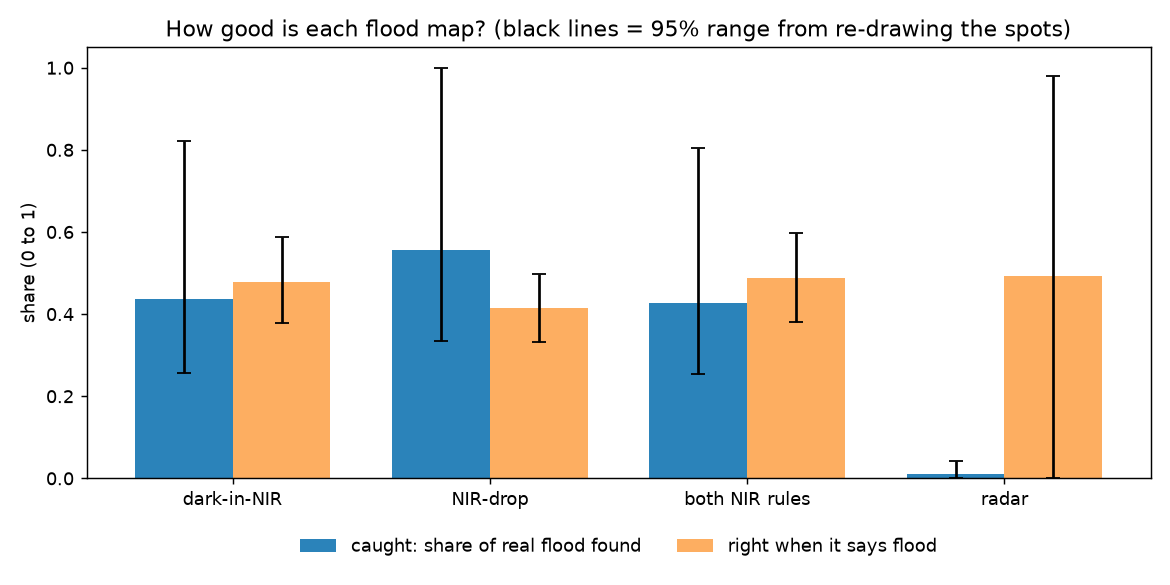

In [2]:
display(Image(filename='../figures/05_map_scores.png'))

## What we learned
- **The near-infrared maps catch about half the flood, and about half of what they call flood is real** (dark-in-NIR: caught 44%, right 48%). Ranges are wide: caught 26-82%.
- **Overall accuracy (96%) hides everything:** "say dry everywhere" also scores 96%. Recall and precision are the honest grades.
- **Radar (one band, one cutoff) caught about 1% of the flood.** It sees only deep open water.
- **Missed flood** is mostly water at tree edges and under trees (example spots s162, s249).
- **False alarms** include dark plowed fields (bare soil is also dark in near-infrared), roofs and shadows.
- **Estimated real flood in the cloud-free part of the box: about 12 km²**, but this rests heavily on the 2 "dry" spots I labeled water (each stands for about 3,000 pixels), so it is uncertain.
- **How trustworthy are my labels?** On 40 spots re-labeled a second time: same answer 65% of the time, 90% when neither pass said can't tell. Changes never went from water to not water. Swapping in the second-look answers moves the grades by only 1-2 points.